# SLU11 - Tree-based models: Exercises

⚠️  You will need graphviz for some of the exercises. Please follow the installation instructions in the README if you did not install it yet.

In [1]:
import inspect
import json
import hashlib

import pandas as pd
import numpy as np

from IPython.display import Image
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

import utils

We will use the hiking weather data from the learning notebook:

In [2]:
data = utils.make_data()
data.head()

,Outlook,Temperature,Humidity,Windy,Class
0,sunny,hot,high,false,0
1,sunny,hot,high,true,0
2,overcast,hot,high,false,1
3,rain,mild,high,false,1
4,rain,cool,normal,false,1


## Exercise 1 - Decision Trees

### 1.1 Gini impurity

Used by the CART algorithm for classification, Gini impurity is an alternative to entropy.

Similarly to entropy, it is a way to measure node homogeneity. As such, it can be used to identify promising splits.

Take $p$ as the probability of the positive class, i.e., the proportion of positive cases in the set. The Gini impurity is given by:

$$I_G(p)= 1 - p^2 - (1-p)^2$$

It measures how often a randomly chosen element from the set would be incorrectly labeled.

Implement it in the function below.

In [3]:
def gini(p):
    """ 
    Returns the Gini impurity for the given probability
    
    Args:
        p (float): probability of the positive class
        
    Returns:
        (float): Gini impurity for the given probability
    """
    
    # YOUR CODE HERE
    return 1.0 - p**2 - (1 - p)**2

In [4]:

assert isinstance(gini(p=0),float), 'The output should be a float.'
assert  hashlib.sha256(json.dumps(str(gini(p=0))).encode()).hexdigest() == \
'16522468b17d5af6df90b05f6f6b8a1258ecb7b824dab04bfc63e1ed623558c7', 'The calculated gini impurity is not correct.'
assert  hashlib.sha256(json.dumps(str(gini(p=1/6))).encode()).hexdigest() == \
'75116388ece71b50aaaaf8abb686c87975d70a06fce6b74ced563f768b4762c4', 'The calculated gini impurity is not correct.'
assert  hashlib.sha256(json.dumps(str(gini(p=1/3))).encode()).hexdigest() == \
'9c33f8289cfa4048673daafd4e8fe1290e79d77f0cec5378b80f8b7c36b3d3fc', 'The calculated gini impurity is not correct.'
assert  hashlib.sha256(json.dumps(str(gini(p=1/2))).encode()).hexdigest() == \
'55a1a301b2e39a34ca61eee36a76e8c97ad7c2d71a91906baad643dcfc1f2928', 'The calculated gini impurity is not correct.'

### 1.2 Applying the Gini impurity

#### 1.2.1 Single node

Compute the Gini impurity of a node with all samples with normal humidity.

In the first step, define a function that computes the probability of the positive class at the given node.

Then use the function to calculate the probability and the Gini impurity for a node that includes all instances where $x_i^{Humidity}$ is `'normal'`.

Note that `'normal'` is a string, not a boolean.

In [5]:
def compute_probability(node):
    """ 
    Returns the probability of the positive class at the given node.
    
    Args:
        node (pd.DataFrame): samples belonging to the node,
                             a subset of the data dataframe
        
    Returns:
        (float): probability of the positive class at the given node
    """

    # YOUR CODE HERE
    return node['Class'].mean()
# Now 
# single_node_gini = ...
# YOUR CODE HERE
normal_humidity = data[data['Humidity'] == 'normal']
single_node_gini = gini(compute_probability(normal_humidity))

In [6]:
assert hashlib.sha256(json.dumps(str(single_node_gini)).encode()).hexdigest() == \
'e240cf038f4b3a3b865762f0420828c390f8d90b0e7de9aa8550b4bd9105063f', "Are you computing the probability for the right node? \
Are you checking all instances where Class is TRUE?" 

#### 1.2.2 Single feature

Write a function to compute the mean Gini impurity of branching the given data on the given feature.

In [7]:
def mean_impurity(data, feature_name):
    """ 
    Returns the mean Gini impurity of branching the given data on the given feature
    
    Args:
        data (pd.DataFrame): samples dataframe
        feature_name (string): feature on which the node should branch
        
    Returns:
        (float): mean impurity of branching the given data on the given feature
    """
    # YOUR CODE HERE
    impurities = [
        gini(compute_probability(node))
        for _, node in data.groupby(feature_name)
    ]
    return float(np.mean(impurities))

In [8]:
assert isinstance(mean_impurity(data, 'Outlook'),float), 'The output should be a float.'
assert hashlib.sha256(json.dumps(str(round(mean_impurity(data, 'Outlook'),4))).encode()).hexdigest() == \
'5830db5516c4425f35f1e07c77099a86a9f9ac935da32df698db4a6790b1e544', 'The mean impurity for the Outlook feature is not correct.'
assert hashlib.sha256(json.dumps(str(round(mean_impurity(data, 'Humidity'),4))).encode()).hexdigest() == \
'27d59dff61e8ae2b23d553db74d8be2ef5d343f8dcb41cb88a0523eeba8e20e2', 'The mean impurity for the Humidity feature is not correct.'
assert hashlib.sha256(json.dumps(str(round(mean_impurity(data, 'Temperature'),4))).encode()).hexdigest() == \
'3157bf686408d38a62a06be8ed1c460ac1565d6613ce0e792665a5a82fe4f99d', 'The mean impurity for the Temperature feature is not correct.'
assert hashlib.sha256(json.dumps(str(round(mean_impurity(data, 'Windy'),4))).encode()).hexdigest() == \
'9e6b44d567ead782bf355adea0554cba7dbf36286397d3d995ac26023e47f9f8', 'The mean impurity for the Windy feature is not correct.'

### 1.3 Analyzing a decision tree

#### 1.3.1 DecisionTreeClassifier

Import and train a DecisionTreeClassifier using the provided features X and target y.

* Set `random_state = 101`
* use the `entropy`criterion

In [9]:
# we will use this data in this exercise
exercise_data = utils.make_exercise_data()
X, y = utils.separate_target_variable(exercise_data)
X = utils.process_categorical_features(X)

In [10]:
# Import the model
# YOUR CODE HERE
import sklearn.tree

# Instantiate the model with random_state=101, and assign it to the variable "model". Then fit it to the data
# model = ...
# YOUR CODE HERE
model = sklearn.tree.DecisionTreeClassifier(criterion='entropy', random_state=101)
model.fit(X, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",101
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sam

In [11]:
assert hashlib.sha256(json.dumps(str(model.get_params())).encode()).hexdigest() == \
'a506fbdfc7b7fe53a0ef12218f267be76af167861b7df9d19dee8d865c995a7e', "Did you set up the model as required?"
assert len(model.predict(X))==len(y), 'Did you fit the model correctly?'

#### 1.3.2 Analyze the resulting tree
The fitted decision tree `model` from the previous exercise is shown here. Examine it and answer questions about it below.

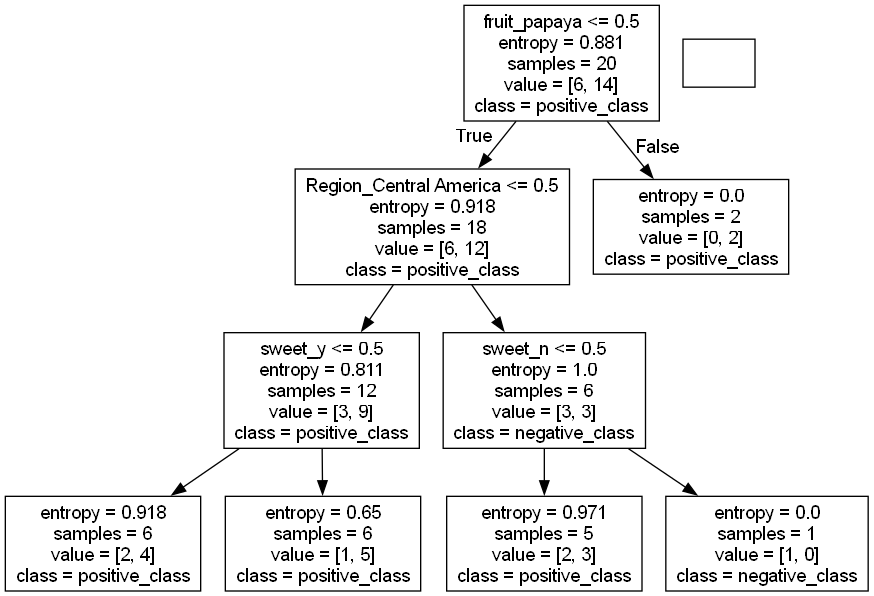

In [12]:
tree = utils.visualize_tree(model, X.columns, ["negative_class", "positive_class"])
Image(tree)

a) A new instance of data has the following features: 

* `fruit` is not equal to `papaya`;
* `Region` is not equal to `Central America`;
* `sweet` is not equal to `y`.

To which class will this decision tree assign this new instance? ('positive_class' or 'negative_class'). Assign the answer to variable `a_answer`.

In [13]:
# a_answer = ...
# YOUR CODE HERE
a_answer = 'positive_class'

b)  One of the four statements below is **false**. Assign its number to variable `b_answer`.

1. When building a decision tree using the ID3 algorithm,  at each split, we select the attribute test that leads to the highest information gain.
2. Decision trees aren't extremely robust to overfitting.
3. We can use a decision tree to represent a set of complex rules.
4. Entropy can be seen as a measure of homogeneity in a set of values. The more entropy, the more homogeneous it will be.

In [14]:
# b_answer = ...
# YOUR CODE HERE
b_answer = '4'

c) What is the name of the most important feature of this decision tree, `model`? Assign it to variable `c_answer`. Feel free to use any functions/methods needed to obtain this answer.

In [15]:
# feature_importances = ...
# c_answer = ...

# YOUR CODE HERE
feature_importances = pd.Series(model.feature_importances_, index=X.columns)
c_answer = feature_importances.idxmax()

In [16]:
final_answer = str(b_answer) + a_answer + c_answer
assert hashlib.sha256(json.dumps(final_answer).encode()).hexdigest() == \
'f8113e64e76abb4a42a94fdf6d07de8ec4fc3ddb36e855e0c185d17a26270c38', "Some answers are wrong!"

## Exercise 2 - Ensemble models

### 2.1 Bagging

Assign the lowercase letter of the **incorrect statement** to the variable `bagging_answer`:

a) Bagging is an ensemble method in which the predictions of several weak learners are combined to generate a final prediction.

b) Bagging involves creating multiple data sets by sampling columns.

c) Bootstrapping, often used when bagging, is the creation of several datasets through row sampling of a main dataset.

d) Bagging helps to deal with overfitting, which is a big risk when using Decision Trees.

In [17]:
# bagging_answer = ...
# YOUR CODE HERE
bagging_answer = 'b'

In [18]:
hashlib.sha256(json.dumps(bagging_answer).encode()).hexdigest()

'c100f95c1913f9c72fc1f4ef0847e1e723ffe0bde0b36e5f36c13f81fe8c26ed'

In [19]:
assert hashlib.sha256(json.dumps(bagging_answer).encode()).hexdigest() == \
'c100f95c1913f9c72fc1f4ef0847e1e723ffe0bde0b36e5f36c13f81fe8c26ed', 'Not correct.'

### 2.2 Random forests

Assign the lowercase letter of the **incorrect statement** to the variable `forest_answer`:

a) We use random feature selection with random forests to force our models to be "creative" and adapt to not having access to the full information, thus increasing diversity inside the ensemble.

b) Random forests aggregate the predictions of multiple models running in parallel.

c) Random forests aggregate the predictions of multiple models running sequentially.

d) Random forests rely on random feature selection before each split.

In [20]:
# forest_answer = ...
# YOUR CODE HERE
forest_answer = 'c'

In [21]:
assert hashlib.sha256(json.dumps(forest_answer).encode()).hexdigest() == \
'879923da020d1533f4d8e921ea7bac61e8ba41d3c89d17a4d14e3a89c6780d5d', 'Not correct.'

### 2.3 - Gradient boosting

Assign the lowercase letter of the **incorrect statement** to the variable `boosting_answer`:

a) Gradient boosting fits individual trees sequentially, to the negative gradients of the previous tree.

b) Gradient boosting is fairly robust to over-fitting so a large number of estimators usually results in worse performance.

c) Gradient boosting can only be used to optimize the squared error loss function.

d) Gradient boosting fits individual trees on the residuals of the previous tree.

In [22]:
# boosting_answer = ...
# YOUR CODE HERE
boosting_answer = 'c'

In [23]:
assert hashlib.sha256(json.dumps(boosting_answer).encode()).hexdigest() == \
'879923da020d1533f4d8e921ea7bac61e8ba41d3c89d17a4d14e3a89c6780d5d', 'Not correct.'